Compare the MS-38 supervised recipe ablations (output stride, normalization, random rescale, evaluation protocol) against the short supervised baseline B1 (40k, 1x head LR), using saved test metrics and confusion matrices.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display

BASELINE = ("None (B1, 40k)", "baseline_r50_short_1xHeadLR/test")
ABLATIONS = {
    "Output stride 8": "abl_os8_short/test",
    "S5Mars normalization": "abl_marsnorm_short/test",
    "No random rescale": "abl_noscale_short/test",
    "Full-image evaluation": "baseline_r50_short_1xHeadLR/test_fullres",  # same B1 model, scored on whole images
}
TRAINING_ABLATIONS = ["Output stride 8", "S5Mars normalization", "No random rescale"]
CLASSES = ["sky", "ridge", "soil", "sand", "bedrock", "rock", "rover", "trace", "hole"]

# Project paths
project_dir = Path.cwd()
if project_dir.name.lower() == "analysis":
    project_dir = project_dir.parent
results_dir = project_dir / "results"
output_dir = project_dir / "analysis" / "results" / "MS-38"
output_dir.mkdir(parents=True, exist_ok=True)

# Load metrics and confusion matrices
runs = dict([BASELINE, *ABLATIONS.items()])
metrics, matrices = {}, {}
for label, run_dir in runs.items():
    path = results_dir / run_dir
    if not (path / "metrics.json").exists():
        raise FileNotFoundError(path / "metrics.json")
    metrics[label] = json.loads((path / "metrics.json").read_text())
    matrices[label] = np.load(path / "confusion.npy")
    print(f"{label}: {run_dir}")

None (B1, 40k): baseline_r50_short_1xHeadLR/test
Output stride 8: abl_os8_short/test
S5Mars normalization: abl_marsnorm_short/test
No random rescale: abl_noscale_short/test
Full-image evaluation: baseline_r50_short_1xHeadLR/test_fullres


### Ablation table (MS-38)
mIoU, mAcc, rock IoU and the share of rock pixels predicted as bedrock, compared with B1.

In [2]:
base = metrics[BASELINE[0]]
rows = []
for label, m in metrics.items():
    rows.append({
        "change": label,
        "mIoU": m["mIoU"],
        "mAcc": m["mAcc"],
        "rock_IoU": m["IoU"]["rock"],
        "rock_to_bedrock_pct": m["rock"]["rock_to_bedrock"],
        "delta_mIoU": m["mIoU"] - base["mIoU"],
        "delta_rock_IoU": m["IoU"]["rock"] - base["IoU"]["rock"],
    })
ablation_df = pd.DataFrame(rows)
ablation_df.to_csv(output_dir / "ablation_table.csv", index=False)
display(ablation_df.round(2))

,change,mIoU,mAcc,rock_IoU,rock_to_bedrock_pct,delta_mIoU,delta_rock_IoU
0,"None (B1, 40k)",67.75,74.80,20.34,74.13,0.00,0.00
1,Output stride 8,64.42,73.12,21.37,73.34,-3.32,1.03
2,S5Mars normalization,64.47,72.15,18.10,77.97,-3.27,-2.24
3,No random rescale,68.48,75.62,24.75,67.10,0.74,4.41
4,Full-image evaluation,67.12,74.40,20.44,73.93,-0.63,0.10


### Per-class IoU
IoU per class for each row, and the change against B1 in IoU points.

In [3]:
iou_df = pd.DataFrame({label: m["IoU"] for label, m in metrics.items()}).T[CLASSES]
iou_df["mIoU"] = [m["mIoU"] for m in metrics.values()]
delta_df = iou_df.drop(index=BASELINE[0]) - iou_df.loc[BASELINE[0]]
iou_df.to_csv(output_dir / "per_class_iou.csv", index_label="change")
delta_df.to_csv(output_dir / "per_class_iou_delta.csv", index_label="change")
display(iou_df.round(1))
display(delta_df.round(1))

,sky,ridge,soil,sand,bedrock,rock,rover,trace,hole,mIoU
"None (B1, 40k)",94.0,92.8,82.1,72.8,91.4,20.3,73.8,67.3,15.2,67.7
Output stride 8,92.4,92.2,81.3,70.7,91.4,21.4,60.5,59.8,10.2,64.4
S5Mars normalization,92.4,91.7,82.7,75.8,91.1,18.1,61.3,56.7,10.5,64.5
No random rescale,92.7,92.1,82.6,73.3,91.4,24.7,75.5,70.6,13.3,68.5
Full-image evaluation,91.2,90.7,81.1,72.6,91.4,20.4,73.6,68.7,14.5,67.1


,sky,ridge,soil,sand,bedrock,rock,rover,trace,hole,mIoU
Output stride 8,-1.5,-0.7,-0.7,-2.1,-0.0,1.0,-13.3,-7.5,-5.0,-3.3
S5Mars normalization,-1.5,-1.1,0.7,3.0,-0.4,-2.2,-12.5,-10.6,-4.7,-3.3
No random rescale,-1.2,-0.7,0.5,0.5,-0.0,4.4,1.8,3.3,-1.9,0.7
Full-image evaluation,-2.8,-2.2,-1.0,-0.3,-0.0,0.1,-0.2,1.3,-0.7,-0.6


### Full 9-Class Confusion Matrices (ablations)
Row-normalized test confusion matrices of the three training ablations, in the same style as MS-28; compare with B1's matrix in MS-28.

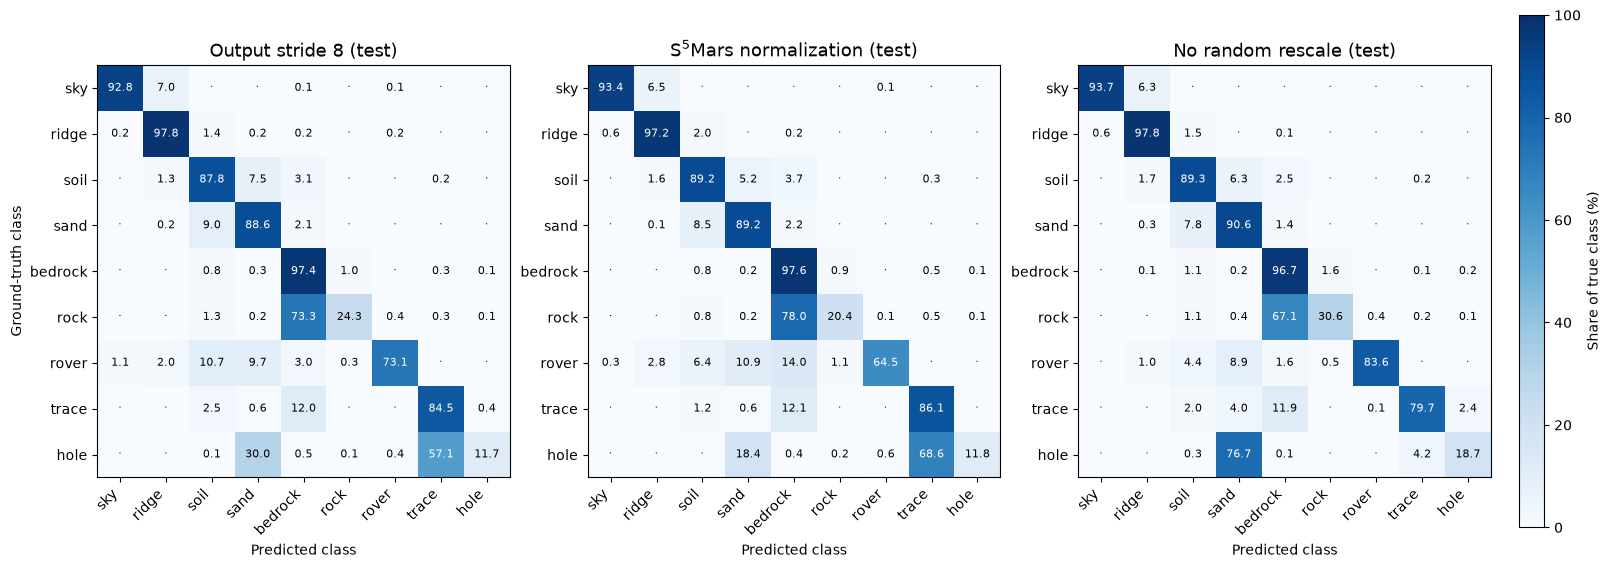

In [4]:
def row_pct(cm):
    row_totals = cm.sum(axis=1, keepdims=True)
    return np.divide(cm.astype(np.float64) * 100, row_totals,
                     out=np.zeros_like(cm, dtype=np.float64), where=row_totals != 0)

base_pct = row_pct(matrices[BASELINE[0]])

fig, axes = plt.subplots(1, len(TRAINING_ABLATIONS), figsize=(16, 5.6), constrained_layout=True)
for ax, label in zip(axes, TRAINING_ABLATIONS):
    cm_pct = row_pct(matrices[label])
    heatmap = ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
    ax.set_title(label.replace("S5Mars", "S$^5$Mars") + " (test)", fontsize=13)
    ax.set_xticks(np.arange(len(CLASSES)), CLASSES, rotation=45, ha="right")
    ax.set_yticks(np.arange(len(CLASSES)), CLASSES)
    ax.set_xlabel("Predicted class")

    # Annotate each cell with its share of the ground-truth class, in %.
    for row in range(len(CLASSES)):
        for col in range(len(CLASSES)):
            value = cm_pct[row, col]
            annotation = f"{value:.1f}" if value >= 0.05 else "·"
            ax.text(col, row, annotation, ha="center", va="center",
                    color="white" if value >= 55 else "black", fontsize=8)

axes[0].set_ylabel("Ground-truth class")
fig.colorbar(heatmap, ax=axes, fraction=0.02, pad=0.02, label="Share of true class (%)")
for ext in ("png", "pdf"):
    fig.savefig(output_dir / f"confusion_ablations_test.{ext}", dpi=250, bbox_inches="tight")
plt.show()